## 1. Imports, configuration, and reproducibility

Imports the libraries used for image handling, data processing, model training, and evaluation. Sets random seeds, configures the Kaggle dataset paths, creates an output folder, and chooses a GPU when CUDA is available. **If running outside Kaggle, change the dataset paths in this cell.**

In [1]:
# PURPOSE: Import dependencies, set reproducible random seeds, configure dataset/output paths, and select CPU/GPU.
import os
import random
import time
import json
import copy
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageFilter, ImageEnhance

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.transforms import InterpolationMode

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Exact Kaggle paths
BASE_DIR = Path(
    "/kaggle/input/datasets/dheerajlohit"
)

TRAIN_IMAGE_DIR = (
    BASE_DIR / "train-and-test" / "Train"
)

TEST_IMAGE_DIR = (
    BASE_DIR / "train-and-test" / "Test"
)

CSV_DIR = BASE_DIR / "csv-files"

TRAIN_CSV = CSV_DIR / "Train.csv"
TEST_CSV = CSV_DIR / "Test.csv"
META_CSV = CSV_DIR / "Meta.csv"

# Output directory
OUTPUT_DIR = Path(
    "/kaggle/working/traffic_sign_results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Device configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Training image folder exists:", TRAIN_IMAGE_DIR.exists())
print("Testing image folder exists:", TEST_IMAGE_DIR.exists())
print("Training CSV exists:", TRAIN_CSV.exists())
print("Testing CSV exists:", TEST_CSV.exists())
print("Metadata CSV exists:", META_CSV.exists())
print("Output directory:", OUTPUT_DIR)

Device: cuda
Training image folder exists: True
Testing image folder exists: True
Training CSV exists: True
Testing CSV exists: True
Metadata CSV exists: True
Output directory: /kaggle/working/traffic_sign_results


## 2. Load the CSV files

Reads the training, testing, and class-metadata CSV files. It prints their dimensions, column names, and example rows so you can confirm that the expected dataset files loaded correctly.

In [2]:
# PURPOSE: Read the dataset CSV files and inspect their columns and sample records.
train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
meta_df = pd.read_csv(META_CSV)

# Remove accidental spaces in column names
train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()
meta_df.columns = meta_df.columns.str.strip()

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("\nTraining dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)
print("Metadata shape:", meta_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("\nMetadata columns:")
print(meta_df.columns.tolist())

print("\nTraining sample:")
display(train_df.head())

print("\nTesting sample:")
display(test_df.head())

print("\nMetadata sample:")
display(meta_df.head())

DATASET INFORMATION

Training dataset shape: (39209, 8)
Testing dataset shape: (12630, 8)
Metadata shape: (43, 5)

Training columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Testing columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Metadata columns:
['Path', 'ClassId', 'ShapeId', 'ColorId', 'SignId']

Training sample:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png



Testing sample:


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,Test/00000.png
1,42,45,5,5,36,40,1,Test/00001.png
2,48,52,6,6,43,47,38,Test/00002.png
3,27,29,5,5,22,24,33,Test/00003.png
4,60,57,5,5,55,52,11,Test/00004.png



Metadata sample:


,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22


## 3. Validate labels and locate images

Checks that the CSV files contain `Path` and `ClassId`, indexes image files, and matches CSV paths to files on disk. This helps handle datasets whose CSV paths contain extra `Train/` or `Test/` folders. It raises a clear error if an image cannot be found.

In [3]:
# PURPOSE: Validate the CSV schema and resolve each CSV image path to a real image file.
# Verify required columns
required_columns = {"Path", "ClassId"}

if not required_columns.issubset(train_df.columns):
    raise ValueError(
        f"Train.csv must contain {required_columns}. "
        f"Found: {train_df.columns.tolist()}"
    )

if not required_columns.issubset(test_df.columns):
    raise ValueError(
        f"Test.csv must contain {required_columns}. "
        f"Found: {test_df.columns.tolist()}"
    )


IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".ppm", ".bmp"
}


def build_image_index(image_root):
    """Index image files by relative path and filename."""

    index = {}

    for root, dirs, files in os.walk(image_root):
        for filename in files:

            file_path = Path(root) / filename

            if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            relative_path = file_path.relative_to(
                image_root
            ).as_posix()

            index.setdefault(
                relative_path.lower(),
                str(file_path)
            )

            index.setdefault(
                filename.lower(),
                str(file_path)
            )

    return index


train_image_index = build_image_index(
    TRAIN_IMAGE_DIR
)

test_image_index = build_image_index(
    TEST_IMAGE_DIR
)

print("Training images found:", len(train_image_index))
print("Testing images found:", len(test_image_index))


def resolve_image_path(csv_path, image_root, image_index):
    """Match a CSV image path to an existing image."""

    original = str(csv_path).replace("\\", "/")
    path = Path(original)

    candidates = [
        original,
        path.as_posix(),
        path.name
    ]

    # Remove a leading Train/ or Test/ directory
    parts = list(path.parts)

    if parts and parts[0].lower() in {"train", "test"}:
        parts = parts[1:]

        if parts:
            candidates.append(
                Path(*parts).as_posix()
            )

    # Try the image root with the original path
    candidates.append(
        (image_root / path).as_posix()
    )

    # Try the image root without the leading folder
    if parts:
        candidates.append(
            (image_root / Path(*parts)).as_posix()
        )

    for candidate in candidates:

        candidate_path = Path(candidate)

        if candidate_path.is_file():
            return str(candidate_path)

        key = candidate.replace("\\", "/").lower()

        if key in image_index:
            return image_index[key]

    raise FileNotFoundError(
        f"Could not locate image '{original}' "
        f"inside '{image_root}'."
    )


train_df["ImagePath"] = [
    resolve_image_path(
        p,
        TRAIN_IMAGE_DIR,
        train_image_index
    )
    for p in train_df["Path"]
]

test_df["ImagePath"] = [
    resolve_image_path(
        p,
        TEST_IMAGE_DIR,
        test_image_index
    )
    for p in test_df["Path"]
]

train_df["ClassId"] = pd.to_numeric(
    train_df["ClassId"],
    errors="raise"
).astype(int)

test_df["ClassId"] = pd.to_numeric(
    test_df["ClassId"],
    errors="raise"
).astype(int)

print("\nImage paths matched successfully.")

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nExample training image:")
print(train_df.iloc[0]["ImagePath"])

print("\nExample testing image:")
print(test_df.iloc[0]["ImagePath"])

Training images found: 78418
Testing images found: 25260

Image paths matched successfully.
Training records: 39209
Testing records: 12630

Example training image:
/kaggle/input/datasets/dheerajlohit/train-and-test/Train/Train/20/00020_00000_00000.png

Example testing image:
/kaggle/input/datasets/dheerajlohit/train-and-test/Test/Test/00000.png


## 4. Check class distribution and prepare labels

Checks which class IDs appear in the train and test data, reports the class distribution, and prepares consistent label indices for the neural networks. The model predicts these zero-based indices; the mapping back to the dataset's original class IDs is saved later.

In [4]:
# PURPOSE: Inspect class labels/distribution and prepare a consistent label mapping for training.
# Check class labels
class_ids = sorted(
    train_df["ClassId"].unique().tolist()
)

test_class_ids = sorted(
    test_df["ClassId"].unique().tolist()
)

print("Training classes:", len(class_ids))
print("Testing classes:", len(test_class_ids))

print("\nTraining class distribution:")

display(
    train_df["ClassId"]
    .value_counts()
    .sort_index()
    .to_frame("ImageCount")
)

# Ensure all test labels have a corresponding training class
unknown_test_classes = (
    set(test_class_ids) - set(class_ids)
)

if unknown_test_classes:
    raise ValueError(
        "Test data contains classes absent from training: "
        f"{sorted(unknown_test_classes)}"
    )

# Create a consistent mapping to output indices
label_to_index = {
    label: index
    for index, label in enumerate(class_ids)
}

index_to_label = {
    index: label
    for label, index in label_to_index.items()
}

NUM_CLASSES = len(class_ids)

train_df["LabelIndex"] = train_df["ClassId"].map(
    label_to_index
)

test_df["LabelIndex"] = test_df["ClassId"].map(
    label_to_index
)

# Stratified split preserves class proportions
train_part, val_part = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["LabelIndex"]
)

train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nFinal dataset split:")
print("Training images:", len(train_part))
print("Validation images:", len(val_part))
print("Testing images:", len(test_df))
print("Number of classes:", NUM_CLASSES)

Training classes: 43
Testing classes: 43

Training class distribution:


,ImageCount
ClassId,
0,210
1,2220
2,2250
3,1410
4,1980
5,1860
6,420
7,1440
8,1410



Final dataset split:
Training images: 31367
Validation images: 7842
Testing images: 12630
Number of classes: 43


## 5. View example images

Displays a small sample of traffic-sign images and their class IDs. This is a visual sanity check to catch incorrect paths or unexpected image content before training.

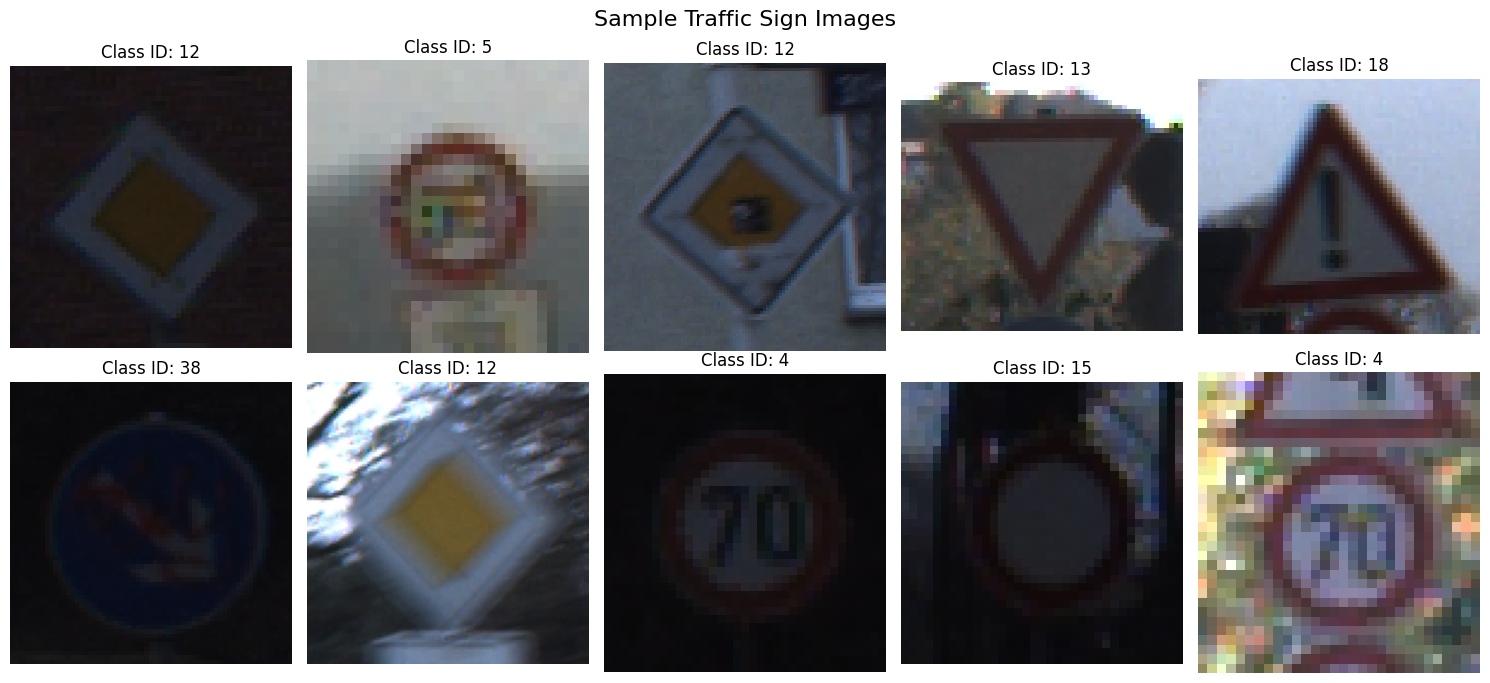

In [5]:
# PURPOSE: Display example images to visually verify that the dataset paths and labels look correct.
fig, axes = plt.subplots(
    2, 5,
    figsize=(15, 7)
)

for i, ax in enumerate(axes.flat):

    row = train_part.iloc[i]

    image = Image.open(
        row["ImagePath"]
    ).convert("RGB")

    ax.imshow(image)

    ax.set_title(
        f"Class ID: {row['ClassId']}"
    )

    ax.axis("off")

plt.suptitle(
    "Sample Traffic Sign Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 6. Preprocessing and data loaders

Resizes images to 96 × 96 pixels and normalizes them using ImageNet statistics. Random rotation and brightness/contrast changes are applied only to training images as augmentation. The dataset class can also apply Gaussian blur or low-light brightness reduction for evaluation. DataLoaders create batches.

In [6]:
# PURPOSE: Define image preprocessing, degradation conditions, datasets, and batched data loaders.
IMAGE_SIZE = 96
BATCH_SIZE = 64
NUM_WORKERS = 2

# ImageNet normalization for MobileNetV3
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.RandomRotation(8),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])


class TrafficSignDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None,
        condition="clean"
    ):
        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform
        self.condition = condition

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image = Image.open(
            row["ImagePath"]
        ).convert("RGB")

        label = int(row["LabelIndex"])

        if self.condition == "blur":

            image = image.filter(
                ImageFilter.GaussianBlur(radius=2)
            )

        elif self.condition == "low_light":

            image = ImageEnhance.Brightness(
                image
            ).enhance(0.35)

        if self.transform is not None:
            image = self.transform(image)

        return image, label


train_dataset = TrafficSignDataset(
    train_part,
    transform=train_transform
)

val_dataset = TrafficSignDataset(
    val_part,
    transform=eval_transform
)

test_datasets = {
    "Clean": TrafficSignDataset(
        test_df,
        transform=eval_transform,
        condition="clean"
    ),

    "Gaussian Blur": TrafficSignDataset(
        test_df,
        transform=eval_transform,
        condition="blur"
    ),

    "Low Light": TrafficSignDataset(
        test_df,
        transform=eval_transform,
        condition="low_light"
    )
}

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loaders = {
    name: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda")
    )
    for name, dataset in test_datasets.items()
}

print("Preprocessing completed.")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

for name, loader in test_loaders.items():
    print(name, "batches:", len(loader))

Preprocessing completed.
Image size: 96
Batch size: 64
Training batches: 491
Validation batches: 123
Clean batches: 198
Gaussian Blur batches: 198
Low Light batches: 198


## 7. Majority-class baseline

Creates a simple baseline that always predicts the most common training class. This provides a basic reference point: a trained model should perform meaningfully better than this simple strategy.

In [7]:
# PURPOSE: Measure a simple majority-class baseline for comparison with trained models.
majority_class = int(
    train_part["LabelIndex"].value_counts().idxmax()
)

print("Majority class index:", majority_class)
print(
    "Original ClassId:",
    index_to_label[majority_class]
)


def baseline_predict(loader):

    y_true = []
    y_pred = []

    for images, labels in loader:

        y_true.extend(
            labels.numpy().tolist()
        )

        y_pred.extend(
            [majority_class] * len(labels)
        )

    return (
        np.array(y_true),
        np.array(y_pred)
    )


baseline_results = []

for condition, loader in test_loaders.items():

    y_true, y_pred = baseline_predict(loader)

    baseline_results.append({
        "Model": "Majority Baseline",
        "Condition": condition,
        "Accuracy": accuracy_score(
            y_true, y_pred
        ),
        "Macro F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    })

baseline_df = pd.DataFrame(
    baseline_results
)

display(
    baseline_df.round(4)
)

Majority class index: 2
Original ClassId: 2


,Model,Condition,Accuracy,Macro F1,Macro Recall
0,Majority Baseline,Clean,0.0594,0.0026,0.0233
1,Majority Baseline,Gaussian Blur,0.0594,0.0026,0.0233
2,Majority Baseline,Low Light,0.0594,0.0026,0.0233


## 8. Build the custom CNN

Defines a convolutional neural network with convolution, batch normalization, ReLU, and max-pooling layers. Adaptive average pooling reduces the feature map to a fixed size, and dropout helps regularize the final classifier. The output layer predicts one of the traffic-sign classes.

In [8]:
# PURPOSE: Define and initialize the custom convolutional neural network classifier.
class CustomCNN(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x


cnn_model = CustomCNN(
    num_classes=NUM_CLASSES
).to(DEVICE)

print(cnn_model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2)

## 9. Training and validation functions

Defines reusable functions to measure loss/accuracy and train a model. Each epoch updates weights on training batches, then evaluates on validation data. The weights from the epoch with the best validation accuracy are restored at the end.

In [9]:
# PURPOSE: Define reusable training and validation routines, including best-validation-weight restoration.
def evaluate_loss_accuracy(model, loader):

    model.eval()

    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )


def train_model(
    model,
    train_loader,
    val_loader,
    epochs=5,
    learning_rate=0.001
):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    best_val_accuracy = -1.0

    best_weights = copy.deepcopy(
        model.state_dict()
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            total_correct += (
                predictions == labels
            ).sum().item()

            total_samples += labels.size(0)

        train_loss = total_loss / total_samples

        train_accuracy = (
            total_correct / total_samples
        )

        val_loss, val_accuracy = (
            evaluate_loss_accuracy(
                model,
                val_loader
            )
        )

        history["train_loss"].append(
            float(train_loss)
        )

        history["val_loss"].append(
            float(val_loss)
        )

        history["train_accuracy"].append(
            float(train_accuracy)
        )

        history["val_accuracy"].append(
            float(val_accuracy)
        )

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            best_weights = copy.deepcopy(
                model.state_dict()
            )

    model.load_state_dict(best_weights)

    training_time = time.time() - start_time

    print(
        f"\nTraining time: {training_time:.2f} seconds"
    )

    print(
        f"Best validation accuracy: "
        f"{best_val_accuracy:.4f}"
    )

    return model, history, training_time

## 10. Train the custom CNN

Trains the custom CNN for five epochs using the training and validation DataLoaders. The cell records the training history and elapsed time for later plots and comparisons. Training time depends on your hardware.

In [10]:
# PURPOSE: Train the custom CNN and store its learning history and training time.
cnn_model, cnn_history, cnn_training_time = train_model(
    cnn_model,
    train_loader,
    val_loader,
    epochs=5,
    learning_rate=0.001
)

Epoch 1/5 | Train Loss: 2.8969 | Train Acc: 0.1947 | Val Loss: 2.5187 | Val Acc: 0.2867
Epoch 2/5 | Train Loss: 2.4416 | Train Acc: 0.2973 | Val Loss: 2.2032 | Val Acc: 0.3744
Epoch 3/5 | Train Loss: 2.1711 | Train Acc: 0.3574 | Val Loss: 2.1927 | Val Acc: 0.3568
Epoch 4/5 | Train Loss: 1.9877 | Train Acc: 0.3998 | Val Loss: 1.9438 | Val Acc: 0.4209
Epoch 5/5 | Train Loss: 1.8251 | Train Acc: 0.4392 | Val Loss: 1.6655 | Val Acc: 0.4836

Training time: 246.52 seconds
Best validation accuracy: 0.4836


## 11. Set up MobileNetV3-Small transfer learning

Loads MobileNetV3-Small with pretrained ImageNet weights and replaces its final classification layer with a layer for this dataset's classes. An internet connection may be required the first time the pretrained weights are downloaded.

In [11]:
# PURPOSE: Load pretrained MobileNetV3-Small and replace its final layer for traffic-sign classes.
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

try:

    weights = MobileNet_V3_Small_Weights.DEFAULT

    mobile_model = mobilenet_v3_small(
        weights=weights
    )

    print(
        "Pretrained MobileNetV3-Small loaded."
    )

except Exception as e:

    raise RuntimeError(
        "Could not load pretrained MobileNetV3-Small weights. "
        "Check Kaggle Internet settings and try again. "
        f"Original error: {e}"
    )

# Replace the final classification layer
input_features = (
    mobile_model.classifier[-1].in_features
)

mobile_model.classifier[-1] = nn.Linear(
    input_features,
    NUM_CLASSES
)

mobile_model = mobile_model.to(DEVICE)

print("Number of classes:", NUM_CLASSES)
print("MobileNetV3-Small is ready.")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 99.0MB/s]

Pretrained MobileNetV3-Small loaded.
Number of classes: 43
MobileNetV3-Small is ready.


## 12. Train MobileNetV3-Small

Fine-tunes the pretrained MobileNetV3-Small model using the same training and validation data. A smaller learning rate is used than for the custom CNN because the model starts with pretrained weights.

In [12]:
# PURPOSE: Fine-tune MobileNetV3-Small and record its learning history and training time.
mobile_model, mobile_history, mobile_training_time = train_model(
    mobile_model,
    train_loader,
    val_loader,
    epochs=5,
    learning_rate=0.0005
)

Epoch 1/5 | Train Loss: 0.5212 | Train Acc: 0.8429 | Val Loss: 0.0842 | Val Acc: 0.9712
Epoch 2/5 | Train Loss: 0.0593 | Train Acc: 0.9802 | Val Loss: 0.0412 | Val Acc: 0.9860
Epoch 3/5 | Train Loss: 0.0339 | Train Acc: 0.9891 | Val Loss: 0.0350 | Val Acc: 0.9879
Epoch 4/5 | Train Loss: 0.0249 | Train Acc: 0.9922 | Val Loss: 0.0229 | Val Acc: 0.9925
Epoch 5/5 | Train Loss: 0.0257 | Train Acc: 0.9920 | Val Loss: 0.0871 | Val Acc: 0.9807

Training time: 213.60 seconds
Best validation accuracy: 0.9925


## 13. Plot training history

Plots training and validation accuracy/loss over the epochs. These graphs help identify learning progress and possible overfitting, for example when training performance improves while validation performance stalls.

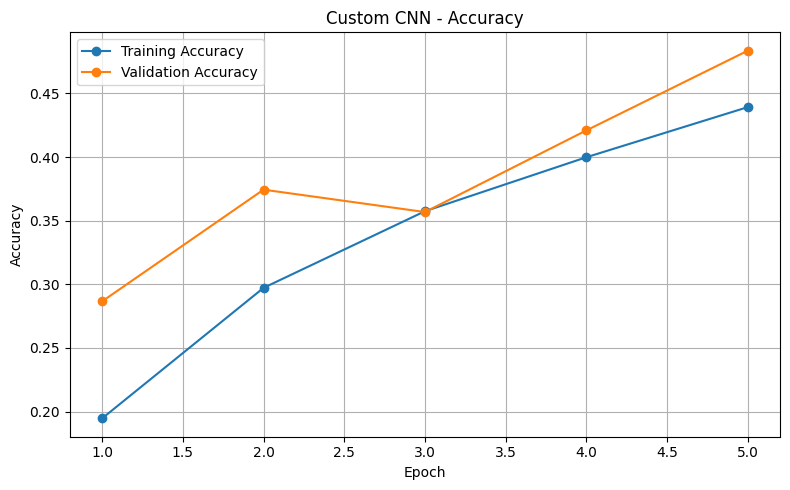

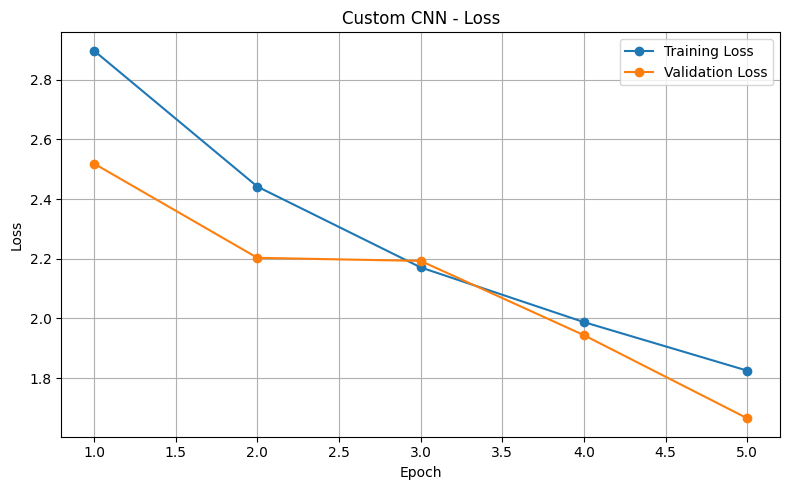

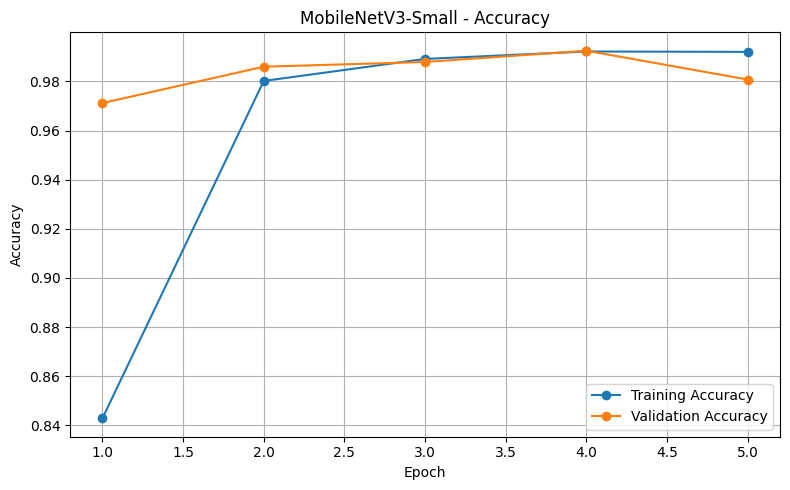

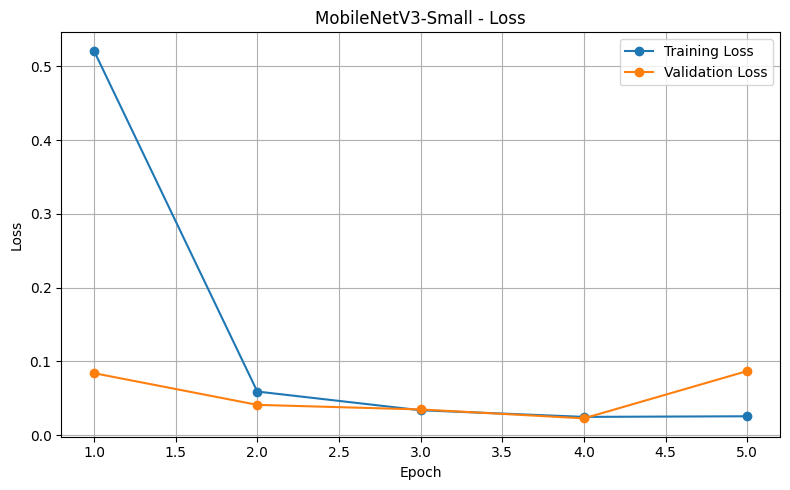

In [13]:
# PURPOSE: Plot training/validation accuracy and loss to inspect learning progress and overfitting.
def plot_training_history(history, model_name):

    epochs = range(
        1,
        len(history["train_loss"]) + 1
    )

    # Accuracy graph
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history["train_accuracy"],
        marker="o",
        label="Training Accuracy"
    )

    plt.plot(
        epochs,
        history["val_accuracy"],
        marker="o",
        label="Validation Accuracy"
    )

    plt.title(
        f"{model_name} - Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Loss graph
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history["train_loss"],
        marker="o",
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        marker="o",
        label="Validation Loss"
    )

    plt.title(
        f"{model_name} - Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


plot_training_history(
    cnn_history,
    "Custom CNN"
)

plot_training_history(
    mobile_history,
    "MobileNetV3-Small"
)

## 14. Evaluate models under image degradation

Generates predictions for both models on clean, Gaussian-blurred, and low-light test images. It calculates accuracy, macro F1-score, and macro recall, and stores predictions for later analysis. Macro metrics give each class equal weight. Results can differ from a previously written README if the notebook is rerun with different data, settings, or random outcomes.

In [14]:
# PURPOSE: Evaluate both models on clean, blurred, and low-light test sets using classification metrics.
def predict_model(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)

            outputs = model(images)

            predictions = outputs.argmax(
                dim=1
            )

            all_predictions.extend(
                predictions.cpu().numpy().tolist()
            )

            all_labels.extend(
                labels.numpy().tolist()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions)
    )


models_to_evaluate = {
    "Custom CNN": cnn_model,
    "MobileNetV3-Small": mobile_model
}

results = baseline_df.to_dict(
    orient="records"
)

saved_predictions = {}

for model_name, model in models_to_evaluate.items():

    print("\n" + "=" * 60)
    print("Evaluating:", model_name)
    print("=" * 60)

    for condition, loader in test_loaders.items():

        y_true, y_pred = predict_model(
            model,
            loader
        )

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        results.append({
            "Model": model_name,
            "Condition": condition,
            "Accuracy": accuracy,
            "Macro F1": macro_f1,
            "Macro Recall": macro_recall
        })

        saved_predictions[
            (model_name, condition)
        ] = (y_true, y_pred)

        print(
            f"{condition}: "
            f"Accuracy={accuracy:.4f}, "
            f"Macro F1={macro_f1:.4f}, "
            f"Macro Recall={macro_recall:.4f}"
        )


results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")

display(
    results_df.round(4)
)


Evaluating: Custom CNN
Clean: Accuracy=0.4208, Macro F1=0.2655, Macro Recall=0.2767
Gaussian Blur: Accuracy=0.1861, Macro F1=0.0892, Macro Recall=0.1293
Low Light: Accuracy=0.2702, Macro F1=0.1868, Macro Recall=0.1895

Evaluating: MobileNetV3-Small
Clean: Accuracy=0.9481, Macro F1=0.9219, Macro Recall=0.9279
Gaussian Blur: Accuracy=0.5563, Macro F1=0.5324, Macro Recall=0.5455
Low Light: Accuracy=0.8806, Macro F1=0.8389, Macro Recall=0.8442

FINAL MODEL COMPARISON


,Model,Condition,Accuracy,Macro F1,Macro Recall
0,Majority Baseline,Clean,0.0594,0.0026,0.0233
1,Majority Baseline,Gaussian Blur,0.0594,0.0026,0.0233
2,Majority Baseline,Low Light,0.0594,0.0026,0.0233
3,Custom CNN,Clean,0.4208,0.2655,0.2767
4,Custom CNN,Gaussian Blur,0.1861,0.0892,0.1293
5,Custom CNN,Low Light,0.2702,0.1868,0.1895
6,MobileNetV3-Small,Clean,0.9481,0.9219,0.9279
7,MobileNetV3-Small,Gaussian Blur,0.5563,0.5324,0.5455
8,MobileNetV3-Small,Low Light,0.8806,0.8389,0.8442


## 15. Compare model metrics visually

Creates bar charts comparing accuracy, macro F1-score, and macro recall across models and image conditions. The y-axis runs from 0 to 1 because these metrics are proportions.

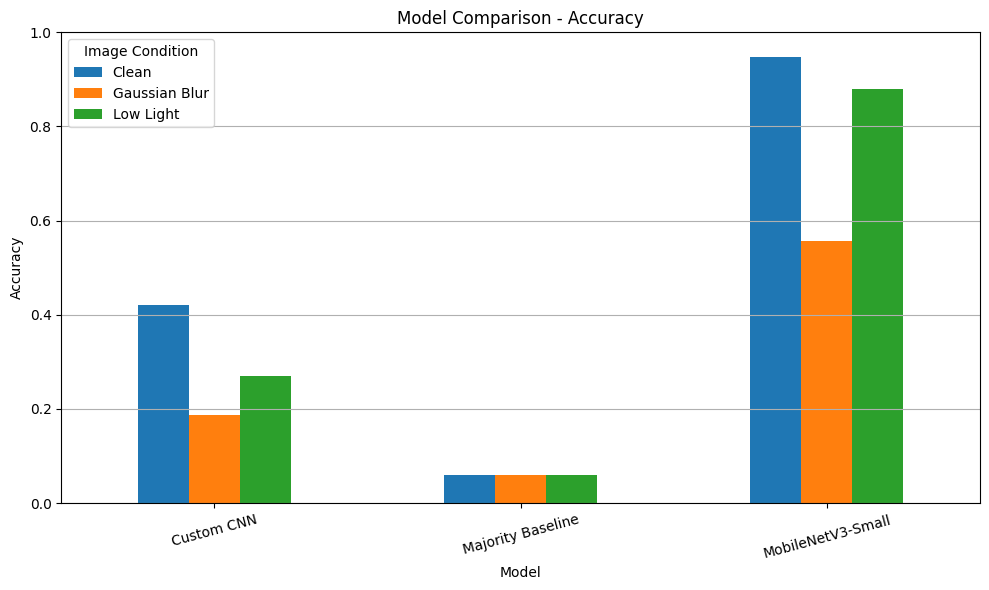

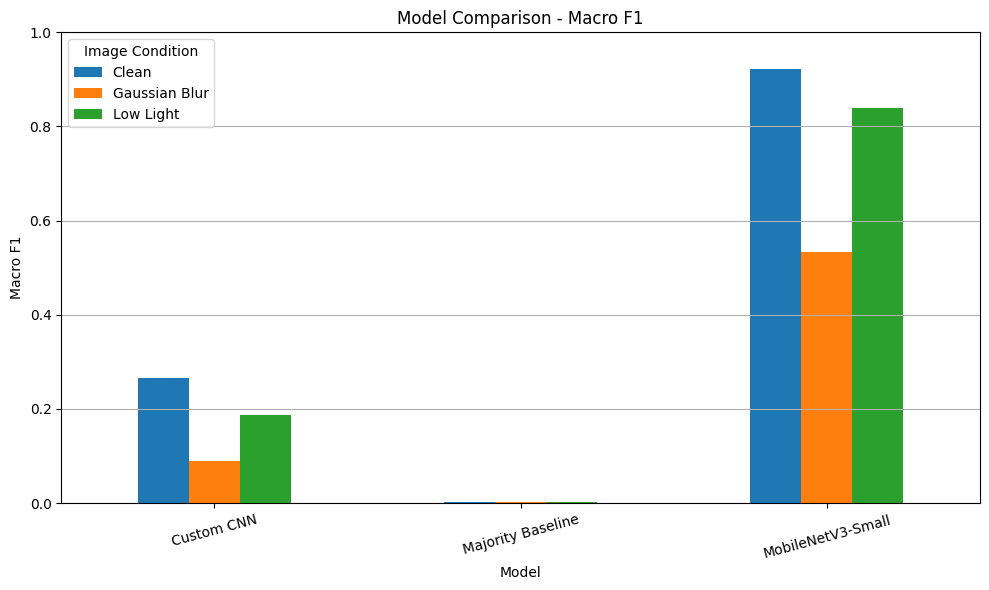

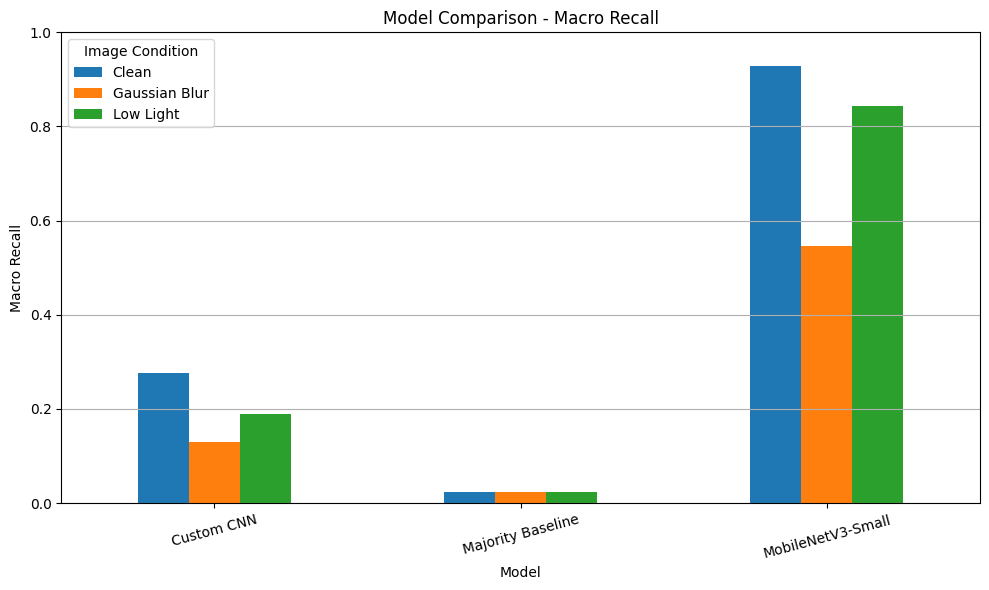

In [15]:
# PURPOSE: Visualize model performance for accuracy, macro F1-score, and macro recall.
metrics = [
    "Accuracy",
    "Macro F1",
    "Macro Recall"
]

for metric in metrics:

    pivot = results_df.pivot(
        index="Model",
        columns="Condition",
        values=metric
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(10, 6)
    )

    ax.set_title(
        f"Model Comparison - {metric}"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel(metric)

    ax.set_ylim(0, 1)

    ax.legend(
        title="Image Condition"
    )

    ax.grid(
        axis="y"
    )

    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

## 16. Detailed classification report

Builds a per-class precision, recall, F1-score, and sample-count report for MobileNetV3-Small on clean test images, displays it, and saves it as a CSV file in the results folder.

In [16]:
# PURPOSE: Generate and save a detailed per-class classification report for clean MobileNet predictions.
y_true, y_pred = saved_predictions[
    ("MobileNetV3-Small", "Clean")
]

class_labels = list(range(NUM_CLASSES))

report_dict = classification_report(
    y_true,
    y_pred,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report_dict
).transpose()

print("CLASSIFICATION REPORT")

display(
    report_df.round(4)
)

report_df.to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

print(
    "Saved classification report:",
    OUTPUT_DIR / "classification_report.csv"
)

CLASSIFICATION REPORT


,precision,recall,f1-score,support
0,0.9153,0.9000,0.9076,60.0000
1,0.9765,0.8667,0.9183,720.0000
2,0.8623,0.9853,0.9197,750.0000
3,0.9677,0.9333,0.9502,450.0000
4,0.9877,0.9712,0.9794,660.0000
5,0.9098,0.9127,0.9113,630.0000
6,0.8759,0.8467,0.8610,150.0000
7,0.9838,0.9422,0.9625,450.0000
8,0.9114,0.9600,0.9351,450.0000
9,0.9958,0.9979,0.9969,480.0000


Saved classification report: /kaggle/working/traffic_sign_results/classification_report.csv


## 17. Confusion matrix

Builds a confusion matrix for MobileNetV3-Small on clean test images. Rows represent true classes and columns represent predicted classes; larger off-diagonal values show which classes are being confused.

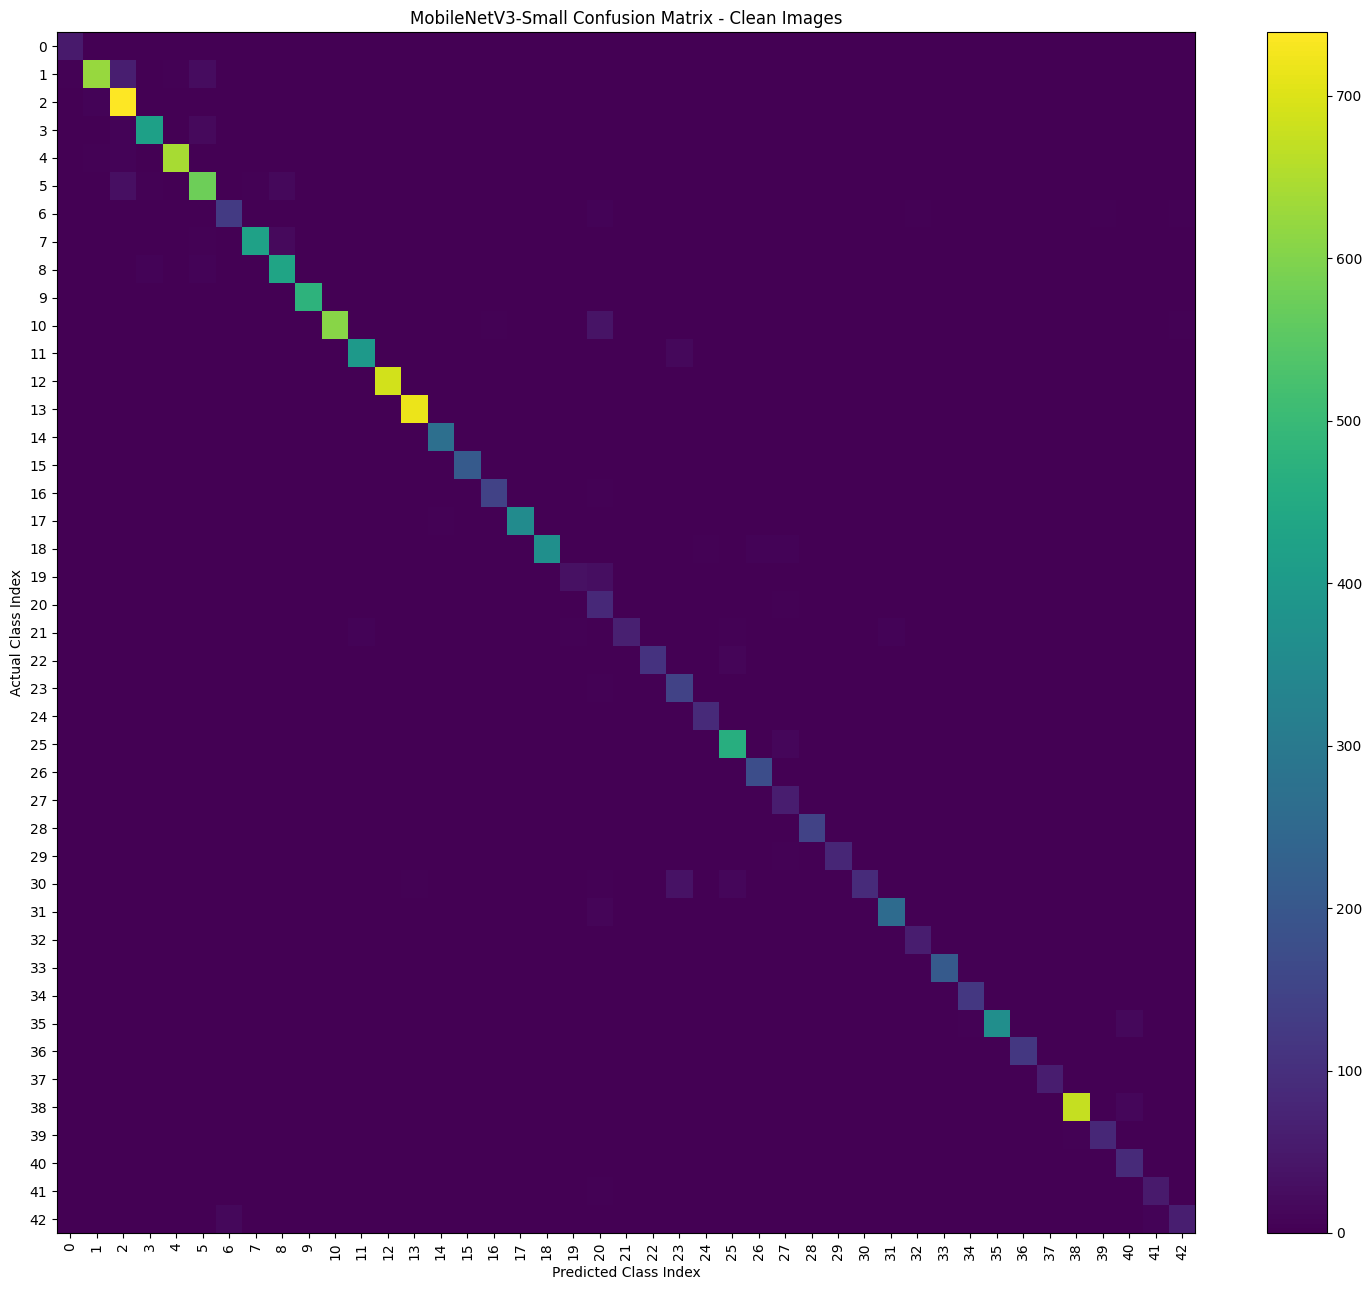

Confusion matrix saved.


In [17]:
# PURPOSE: Visualize which traffic-sign classes are correctly or incorrectly classified.
y_true, y_pred = saved_predictions[
    ("MobileNetV3-Small", "Clean")
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(15, 13))

plt.imshow(
    cm,
    interpolation="nearest",
    aspect="auto"
)

plt.title(
    "MobileNetV3-Small Confusion Matrix - Clean Images"
)

plt.xlabel("Predicted Class Index")
plt.ylabel("Actual Class Index")

plt.xticks(
    range(NUM_CLASSES),
    rotation=90
)

plt.yticks(
    range(NUM_CLASSES)
)

plt.colorbar()
plt.tight_layout()
plt.show()

# Save the matrix
np.savetxt(
    OUTPUT_DIR / "confusion_matrix.csv",
    cm,
    delimiter=",",
    fmt="%d"
)

print("Confusion matrix saved.")

## 18. Find classes with low recall

Calculates recall for each class and condition, then identifies classes the models find difficult. This helps investigate weaknesses that may be hidden by an overall accuracy score.

In [18]:
# PURPOSE: Identify classes with low recall under each model and image condition.
weak_class_rows = []

for model_name in models_to_evaluate:

    for condition in test_loaders:

        y_true, y_pred = saved_predictions[
            (model_name, condition)
        ]

        class_recalls = recall_score(
            y_true,
            y_pred,
            labels=list(range(NUM_CLASSES)),
            average=None,
            zero_division=0
        )

        for class_index, class_recall in enumerate(
            class_recalls
        ):

            weak_class_rows.append({
                "Model": model_name,
                "Condition": condition,
                "ClassIndex": class_index,
                "OriginalClassId": index_to_label[
                    class_index
                ],
                "Recall": float(class_recall)
            })


weak_classes_df = pd.DataFrame(
    weak_class_rows
)

for model_name in models_to_evaluate:

    for condition in test_loaders:

        subset = weak_classes_df[
            (weak_classes_df["Model"] == model_name)
            &
            (weak_classes_df["Condition"] == condition)
        ]

        print(
            f"\nLowest-recall classes: "
            f"{model_name} - {condition}"
        )

        display(
            subset.sort_values(
                "Recall"
            ).head(5)
        )


weak_classes_df.to_csv(
    OUTPUT_DIR / "per_class_recall.csv",
    index=False
)


Lowest-recall classes: Custom CNN - Clean


,Model,Condition,ClassIndex,OriginalClassId,Recall
0,Custom CNN,Clean,0,0,0.0
21,Custom CNN,Clean,21,21,0.0
30,Custom CNN,Clean,30,30,0.0
29,Custom CNN,Clean,29,29,0.0
27,Custom CNN,Clean,27,27,0.0



Lowest-recall classes: Custom CNN - Gaussian Blur


,Model,Condition,ClassIndex,OriginalClassId,Recall
43,Custom CNN,Gaussian Blur,0,0,0.0
49,Custom CNN,Gaussian Blur,6,6,0.0
48,Custom CNN,Gaussian Blur,5,5,0.0
47,Custom CNN,Gaussian Blur,4,4,0.0
58,Custom CNN,Gaussian Blur,15,15,0.0



Lowest-recall classes: Custom CNN - Low Light


...

,Model,Condition,ClassIndex,OriginalClassId,Recall
148,MobileNetV3-Small,Clean,19,19,0.533333
159,MobileNetV3-Small,Clean,30,30,0.600000
171,MobileNetV3-Small,Clean,42,42,0.700000
150,MobileNetV3-Small,Clean,21,21,0.722222
135,MobileNetV3-Small,Clean,6,6,0.846667



Lowest-recall classes: MobileNetV3-Small - Gaussian Blur


,Model,Condition,ClassIndex,OriginalClassId,Recall
178,MobileNetV3-Small,Gaussian Blur,6,6,0.040000
172,MobileNetV3-Small,Gaussian Blur,0,0,0.066667
193,MobileNetV3-Small,Gaussian Blur,21,21,0.088889
202,MobileNetV3-Small,Gaussian Blur,30,30,0.100000
191,MobileNetV3-Small,Gaussian Blur,19,19,0.183333



Lowest-recall classes: MobileNetV3-Small - Low Light


,Model,Condition,ClassIndex,OriginalClassId,Recall
234,MobileNetV3-Small,Low Light,19,19,0.266667
221,MobileNetV3-Small,Low Light,6,6,0.280000
245,MobileNetV3-Small,Low Light,30,30,0.320000
236,MobileNetV3-Small,Low Light,21,21,0.444444
215,MobileNetV3-Small,Low Light,0,0,0.650000


## 19. Save models and experiment outputs

Saves model weights, the model-comparison table, training history, class-label mapping, and experiment configuration. The output folder is configured for Kaggle at `/kaggle/working/traffic_sign_results`; download these outputs from Kaggle if you want to keep them locally or upload selected results to GitHub.

In [19]:
# PURPOSE: Save trained weights and experiment artifacts so results can be reviewed or reused later.
# Save CNN weights
torch.save(
    cnn_model.state_dict(),
    OUTPUT_DIR / "custom_cnn.pth"
)

# Save MobileNetV3 weights
torch.save(
    mobile_model.state_dict(),
    OUTPUT_DIR / "mobilenetv3_small.pth"
)

# Save the comparison table
results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

# Save training history
with open(
    OUTPUT_DIR / "training_history.json",
    "w"
) as file:

    json.dump(
        {
            "Custom CNN": cnn_history,
            "MobileNetV3-Small": mobile_history
        },
        file,
        indent=4
    )

# Save label mappings
with open(
    OUTPUT_DIR / "class_mapping.json",
    "w"
) as file:

    json.dump(
        {
            str(index): int(original_label)
            for index, original_label
            in index_to_label.items()
        },
        file,
        indent=4
    )

# Save metadata for reproducibility
experiment_config = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "number_of_classes": NUM_CLASSES,
    "epochs": 5,
    "cnn_learning_rate": 0.001,
    "mobilenet_learning_rate": 0.0005,
    "blur_radius": 2,
    "low_light_brightness_factor": 0.35,
    "device": str(DEVICE),
    "cnn_training_seconds": cnn_training_time,
    "mobilenet_training_seconds": mobile_training_time
}

with open(
    OUTPUT_DIR / "experiment_config.json",
    "w"
) as file:

    json.dump(
        experiment_config,
        file,
        indent=4
    )

print("All files saved to:", OUTPUT_DIR)

print("\nSaved files:")

for file in sorted(OUTPUT_DIR.iterdir()):

    print(
        file.name,
        "-",
        round(file.stat().st_size / 1024, 2),
        "KB"
    )

All files saved to: /kaggle/working/traffic_sign_results

Saved files:
class_mapping.json - 0.57 KB
classification_report.csv - 2.72 KB
confusion_matrix.csv - 3.7 KB
custom_cnn.pth - 397.49 KB
experiment_config.json - 0.36 KB
mobilenetv3_small.pth - 6234.4 KB
model_comparison.csv - 0.79 KB
per_class_recall.csv - 11.18 KB
training_history.json - 1.59 KB
